# Bobathon ESILV — Complete Pipeline

**Objective:** Predict the UPDRS (Unified Parkinson's Disease Rating Scale) total score for each patient visit.  
**Primary metric:** RMSE (Root Mean Squared Error) — lower is better.  
**Secondary metric:** MAE (Mean Absolute Error).  
**Unit of observation:** One row = one visit for one patient.  
**Key constraint:** Multiple visits per patient → use `GroupKFold(patient_id)` to avoid leakage.

---
## Pipeline overview
1. Imports and configuration
2. Data loading and validation
3. Exploratory data analysis and missing-value analysis
4. Feature and target preparation
5. Helper functions
6. Skore Hub connection
7. Dummy baseline (`01_dummy`)
8. Ridge regression (`02_ridge`)
9. HistGBM default (`03_hist_gradient_boosting`)
10. HistGBM tuned (`04_hist_gradient_boosting_tuned`)
11. skrub tabular_pipeline (`05_tabular_pipeline`)
12. skrub DataOps (`06_dataops`)
13. Feature set D — extended + temporal features
14. HistGBM tuned + feature set D (`07`)
15. XGBoost (`08`)
16. LightGBM (`09`)
17. Optuna-tuned HistGBM (`10`)
18. Optuna-tuned LightGBM (`11`)
19. Weighted OOF ensemble (`12`)
20. Best model — test predictions & submissions
21. Model comparison table
22. Skore Hub URLs
23. Save results CSV


---
## 1. Imports and configuration

In [1]:
from __future__ import annotations

import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skore
import skrub

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder
from skrub import tabular_pipeline as skrub_tabular_pipeline

warnings.filterwarnings('ignore')

# ── Paths ────────────────────────────────────────────────────────────────────
REPO_ROOT       = Path(".").resolve().parent  # notebooks/ is one level below repo root
DATA_DIR        = REPO_ROOT / "data"
SUBMISSIONS_DIR = REPO_ROOT / "submissions"
EXPERIMENTS_DIR = REPO_ROOT / "experiments"
SUBMISSIONS_DIR.mkdir(exist_ok=True)

# ── Constants ─────────────────────────────────────────────────────────────────
PROJECT_NAME  = "bobathon-esilv"
N_SPLITS      = 5
RANDOM_STATE  = 42

# Numeric feature set used in DAY2 steps 1-4
FEATURE_COLS = [
    "sexM", "age_at_diagnosis", "age", "ledd",
    "time_since_intake_on", "time_since_intake_off",
    "on", "off",
]

CATEGORICAL_COLS = ["cohort", "gene", "rater_id"]
DROP_COLS        = ["patient_id", "Index"]

print(f"skore  {skore.__version__}")
print(f"skrub  {skrub.__version__}")
print(f"Repo   {REPO_ROOT}")

skore  0.26.0
skrub  0.11.0
Repo   C:\Users\ASUS\Documents\GitHub\IBM\bobathon-esilv


---
## 2. Data loading and validation

In [2]:
X_train_raw = pd.read_csv(DATA_DIR / "X_train.csv")
y_train_raw = pd.read_csv(DATA_DIR / "y_train.csv")
X_test_raw  = pd.read_csv(DATA_DIR / "X_test.csv")
sample_sub  = pd.read_csv(DATA_DIR / "sample_submission.csv")

# Index alignment check
assert (X_train_raw["Index"] == y_train_raw["Index"]).all(), "Index mismatch X_train vs y_train!"
print("Index alignment: OK")

# DAY2.md pattern: merged visits table
visits = X_train_raw.merge(y_train_raw, on="Index")
y      = visits["target"]   # Series (not DataFrame)

overlap = set(X_train_raw['patient_id']) & set(X_test_raw['patient_id'])
print(f"Train visits : {len(X_train_raw):,}")
print(f"Test  visits : {len(X_test_raw):,}")
print(f"Train patients: {X_train_raw['patient_id'].nunique():,}")
print(f"Test  patients: {X_test_raw['patient_id'].nunique():,}")
print(f"Patient overlap train/test: {len(overlap)}  (0 = no leakage)")

Index alignment: OK
Train visits : 44,590
Test  visits : 11,013
Train patients: 5,576
Test  patients: 1,395
Patient overlap train/test: 0  (0 = no leakage)


---
## 3. Exploratory data analysis and missing-value analysis

In [3]:
print("=== X_train columns & dtypes ===")
print(X_train_raw.dtypes)
print()
X_train_raw.head(3)

=== X_train columns & dtypes ===
Index                      int64
patient_id                   str
cohort                       str
sexM                       int64
gene                         str
age_at_diagnosis         float64
age                      float64
ledd                     float64
time_since_intake_on     float64
time_since_intake_off    float64
rater_id                     str
on                       float64
off                      float64
dtype: object



,Index,patient_id,cohort,sexM,gene,age_at_diagnosis,age,ledd,time_since_intake_on,time_since_intake_off,rater_id,on,off
0,0,IPLP5212,A,0,LRRK2+,48.5,52.1,607.0,1.9,NaN,R36,7.0,NaN
1,1,IPLP5212,A,0,LRRK2+,48.5,53.0,666.0,1.9,17.6,R43,11.0,40.0
2,2,IPLP5212,A,0,LRRK2+,48.5,53.9,717.0,1.2,NaN,R43,6.0,NaN


In [4]:
print("=== Missing values (X_train) ===")
missing = X_train_raw.isna().sum()
pct     = X_train_raw.isna().mean() * 100
mt      = pd.DataFrame({"count": missing, "pct_%": pct.round(1)})
mt      = mt[mt["count"] > 0].sort_values("count", ascending=False)
print(mt.to_string())

print()
print("=== Missing values (X_test) ===")
missing2 = X_test_raw.isna().sum()
pct2     = X_test_raw.isna().mean() * 100
mt2      = pd.DataFrame({"count": missing2, "pct_%": pct2.round(1)})
mt2      = mt2[mt2["count"] > 0].sort_values("count", ascending=False)
print(mt2.to_string())

print("\nNOTE: HistGradientBoostingRegressor handles NaN natively.")
print("      Ridge requires median imputation inside each fold.")

=== Missing values (X_train) ===
                       count  pct_%
time_since_intake_off  35116   78.8
time_since_intake_on   20678   46.4
off                    18913   42.4
ledd                   16338   36.6
gene                   14432   32.4
on                     13220   29.6
age_at_diagnosis        2319    5.2

=== Missing values (X_test) ===
                       count  pct_%
time_since_intake_off   8712   79.1
time_since_intake_on    5262   47.8
off                     4494   40.8
ledd                    4255   38.6
gene                    3526   32.0
on                      3439   31.2
age_at_diagnosis         511    4.6

NOTE: HistGradientBoostingRegressor handles NaN natively.
      Ridge requires median imputation inside each fold.


=== Target distribution ===
count    44590.000000
mean        37.471527
std         16.499679
min          0.000000
25%         25.600000
50%         37.300000
75%         49.300000
max        109.500000
Name: target, dtype: float64
Skewness: 0.051  (near 0 → no log transform needed)


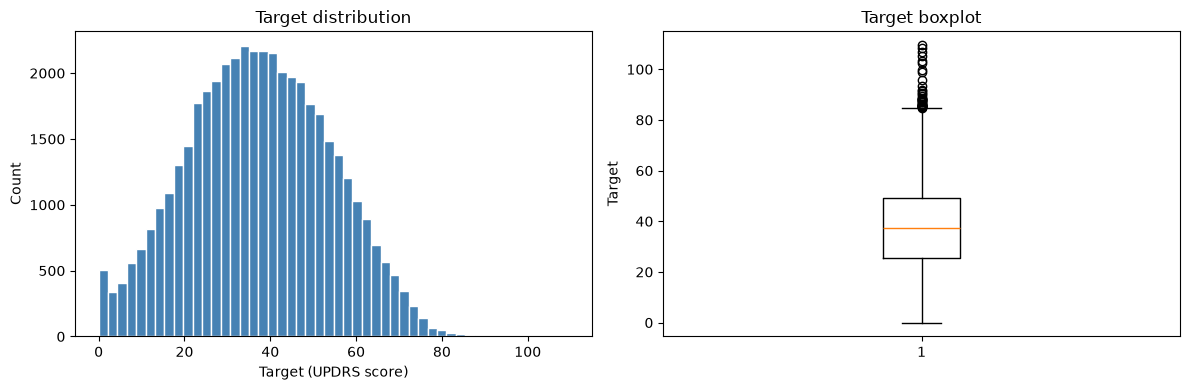

In [5]:
print("=== Target distribution ===")
print(y.describe())
print(f"Skewness: {y.skew():.3f}  (near 0 → no log transform needed)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y, bins=50, color='steelblue', edgecolor='white')
axes[0].set_xlabel("Target (UPDRS score)")
axes[0].set_ylabel("Count")
axes[0].set_title("Target distribution")
axes[1].boxplot(y)
axes[1].set_ylabel("Target")
axes[1].set_title("Target boxplot")
plt.tight_layout()
plt.show()

In [6]:
data_corr = X_train_raw.copy()
data_corr["target"] = y.values
corr = (data_corr.select_dtypes(include=[np.number])
                 .corr()["target"]
                 .drop("target")
                 .sort_values(ascending=False))
print("=== Correlation with target ===")
print(corr.to_string())
print()
print("KEY INSIGHT: 'off' (corr≈0.87) and 'on' (corr≈0.67) dominate — same-visit UPDRS sub-scores.")

=== Correlation with target ===
off                      0.871191
on                       0.668735
age                      0.309816
ledd                     0.298093
age_at_diagnosis         0.133150
time_since_intake_off    0.008291
time_since_intake_on     0.000233
sexM                    -0.001394
Index                   -0.004239

KEY INSIGHT: 'off' (corr≈0.87) and 'on' (corr≈0.67) dominate — same-visit UPDRS sub-scores.


---
## 4. Feature and target preparation

We prepare two feature matrices:
- **`X`** — numeric subset from `FEATURE_COLS` (DAY2 steps 1–4)
- **`X_full`** — all columns except `Index`, `patient_id`, `target` (DAY2 steps 5–6)
- **`X_feat_train`** — engineered features with encoded categoricals (Day 1 style)

GroupKFold splits are computed once and reused across all experiments.

In [7]:
# ── Feature set A: DAY2 numeric columns (steps 1-4) ──────────────────────────
X      = visits[FEATURE_COLS]
X_test = X_test_raw[FEATURE_COLS]

# ── Feature set B: all columns minus ids + target (steps 5-6) ────────────────
X_full      = visits.drop(columns=["Index", "patient_id", "target"])
X_test_full = X_test_raw.drop(columns=["Index", "patient_id"], errors="ignore")

# ── Feature set C: engineered + ordinal-encoded (Day 1 style) ────────────────
def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy()
    d["disease_duration"] = d["age"] - d["age_at_diagnosis"]
    d["on_off_diff"]      = d["off"] - d["on"]
    d["on_off_mean"]      = (d["on"] + d["off"]) / 2.0
    return d.drop(columns=DROP_COLS)

X_feat_train = engineer_features(X_train_raw)
X_feat_test  = engineer_features(X_test_raw)

encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X_feat_train[CATEGORICAL_COLS] = encoder.fit_transform(
    X_feat_train[CATEGORICAL_COLS].astype(str)
)
X_feat_test[CATEGORICAL_COLS] = encoder.transform(
    X_feat_test[CATEGORICAL_COLS].astype(str)
)

# ── Groups and CV splits ──────────────────────────────────────────────────────
groups     = visits["patient_id"]
groups_raw = X_train_raw["patient_id"]   # aligned with X_feat_train rows
gkf        = GroupKFold(n_splits=N_SPLITS)

# Pre-compute splits once (same patient groups, different X shapes)
cv_splits_feat = list(gkf.split(X_feat_train, y, groups_raw))
cv_splits      = list(gkf.split(X, y, groups))
cv_splits_full = list(gkf.split(X_full, y, groups))

# Verify no patient overlap in any fold
for i, (tr, val) in enumerate(cv_splits):
    assert len(set(groups.iloc[tr]) & set(groups.iloc[val])) == 0, f"Fold {i} leakage!"

print(f"GroupKFold(n_splits={N_SPLITS}) by patient_id — no leakage confirmed.")
print(f"Feature set A (numeric): {X.shape}")
print(f"Feature set B (full):    {X_full.shape}")
print(f"Feature set C (engineered): {X_feat_train.shape}")

GroupKFold(n_splits=5) by patient_id — no leakage confirmed.
Feature set A (numeric): (44590, 8)
Feature set B (full):    (44590, 11)
Feature set C (engineered): (44590, 14)


---
## 5. Helper functions

A local `cv_eval()` loop computes per-fold RMSE and MAE without relying on `skore.evaluate`.
This lets us compare models with a consistent metric even when Skore Hub is unavailable.

In [8]:
def cv_eval(
    model,
    X_cv: pd.DataFrame,
    y_cv: pd.Series,
    splits: list,
    *,
    need_imputation: bool = False,
) -> dict:
    """Return per-fold and aggregate RMSE + MAE. No patient leakage."""
    fold_rmse, fold_mae = [], []
    t0 = time.perf_counter()

    for train_idx, val_idx in splits:
        X_tr  = X_cv.iloc[train_idx]
        X_val = X_cv.iloc[val_idx]
        y_tr  = y_cv.iloc[train_idx]
        y_val = y_cv.iloc[val_idx]

        m = clone(model)
        if need_imputation:
            imp   = SimpleImputer(strategy="median")
            X_tr  = imp.fit_transform(X_tr)
            X_val = imp.transform(X_val)

        m.fit(X_tr, y_tr)
        preds = m.predict(X_val)

        fold_rmse.append(float(root_mean_squared_error(y_val, preds)))
        fold_mae.append(float(mean_absolute_error(y_val, preds)))

    elapsed = time.perf_counter() - t0
    return {
        "fold_rmse": fold_rmse,
        "fold_mae":  fold_mae,
        "mean_rmse": float(np.mean(fold_rmse)),
        "std_rmse":  float(np.std(fold_rmse)),
        "mean_mae":  float(np.mean(fold_mae)),
        "std_mae":   float(np.std(fold_mae)),
        "fit_time":  round(elapsed, 3),
    }


def print_cv(key: str, res: dict):
    for i, (r, m) in enumerate(zip(res["fold_rmse"], res["fold_mae"]), 1):
        print(f"  Fold {i}: RMSE={r:.4f}  MAE={m:.4f}")
    print(f"  Mean RMSE : {res['mean_rmse']:.4f} ± {res['std_rmse']:.4f}")
    print(f"  Mean MAE  : {res['mean_mae']:.4f} ± {res['std_mae']:.4f}")
    print(f"  Fit time  : {res['fit_time']:.1f}s  (all folds)")


# Global results registry
all_results: list[dict] = []

---
## 6. Skore Hub connection

We connect once at startup. If Hub is unreachable, local evaluation continues unaffected.

In [9]:
hub_project = None
hub_report_urls: dict[str, str] = {}

def connect_hub():
    global hub_project
    try:
        cfg = json.loads((REPO_ROOT / ".skore").read_text())
        skore.login(mode="hub")
        hub_project = skore.Project(
            name=PROJECT_NAME, mode="hub", workspace=cfg["workspace"]
        )
        hub_url_base = f"https://skore.probabl.ai/{cfg['workspace']}/projects/{PROJECT_NAME}/reports/"
        print(f"Hub connected: {hub_project}")
        return hub_url_base
    except Exception as exc:
        print(f"WARNING: Hub unavailable ({type(exc).__name__}: {exc}). "
              "Reports will NOT be pushed.", file=sys.stderr)
        return None


hub_url_base = connect_hub()

Output()

Hub connected: Project(name='bobathon-esilv', mode='hub', workspace='chml')


Helper to push a report and build the Hub URL:

In [10]:
def push_report(key: str, report) -> str | None:
    """Push report to Hub; return URL or None on failure."""
    if hub_project is None:
        return None
    try:
        hub_project.put(key, report)
        url = f"https://skore.probabl.ai/{hub_project.workspace}/projects/{PROJECT_NAME}/reports/{key}"
        hub_report_urls[key] = url
        print(f"  [Hub] '{key}' pushed → {url}")
        return url
    except Exception as exc:
        print(f"  [Hub] '{key}' push FAILED: {type(exc).__name__}: {exc}", file=sys.stderr)
        return None


def extract_skore_metrics(report) -> dict:
    """Extract mean RMSE and MAE from a skore CrossValidationReport."""
    try:
        df = report.metrics.summarize().frame()
        # column names end in _mean and _std
        mean_cols = [c for c in df.columns if c.endswith("_mean")]
        std_cols  = [c for c in df.columns if c.endswith("_std")]
        mc = mean_cols[0] if mean_cols else df.columns[0]
        sc = std_cols[0]  if std_cols  else df.columns[1]
        rmse_mean = float(df.loc["rmse", mc]) if "rmse" in df.index else float("nan")
        rmse_std  = float(df.loc["rmse", sc]) if "rmse" in df.index else float("nan")
        mae_mean  = float(df.loc["mae",  mc]) if "mae"  in df.index else float("nan")
        mae_std   = float(df.loc["mae",  sc]) if "mae"  in df.index else float("nan")
        fit_time  = float(df.loc["fit_time", mc]) if "fit_time" in df.index else float("nan")
        pred_time = float(df.loc["predict_time", mc]) if "predict_time" in df.index else float("nan")
        return {
            "mean_rmse": rmse_mean, "std_rmse": rmse_std,
            "mean_mae":  mae_mean,  "std_mae":  mae_std,
            "fit_time":  fit_time,  "pred_time": pred_time,
        }
    except Exception as exc:
        print(f"  [Skore] metric extraction failed: {exc}")
        return {}

---
## 7. Experiment 01 — Dummy baseline

Predicts the global mean of the training target. Already on Hub as `01_dummy`.

In [11]:
print("=" * 62)
print("01_dummy  |  DummyRegressor(mean)  |  feature set A  |  GroupKFold")
print("=" * 62)

dummy = DummyRegressor(strategy="mean")

# Local evaluation
res_dummy = cv_eval(dummy, X, y, cv_splits)
print_cv("01_dummy", res_dummy)

# Skore evaluate + Hub push
report_dummy = skore.evaluate(dummy, X, y, splitter=cv_splits)
skore_metrics_dummy = extract_skore_metrics(report_dummy)
# 01_dummy already on Hub — skip re-push to avoid overwriting an identical report
print("  [Hub] '01_dummy' already on Hub — skipping re-push.")
hub_report_urls["01_dummy"] = (
    f"https://skore.probabl.ai/{hub_project.workspace}/projects/{PROJECT_NAME}/reports/01_dummy"
    if hub_project else "(Hub unavailable)"
)

all_results.append({
    "key": "01_dummy",
    "model": "DummyRegressor(mean)",
    "feature_set": "A (numeric)",
    "validation": f"GroupKFold({N_SPLITS})",
    **res_dummy,
    "hub_url": hub_report_urls.get("01_dummy", ""),
    "notes": "Global mean baseline — already on Hub",
})

Output()

01_dummy  |  DummyRegressor(mean)  |  feature set A  |  GroupKFold
  Fold 1: RMSE=16.5852  MAE=13.5284
  Fold 2: RMSE=16.8800  MAE=13.7860
  Fold 3: RMSE=15.9478  MAE=12.9651
  Fold 4: RMSE=16.4698  MAE=13.4612
  Fold 5: RMSE=16.6132  MAE=13.7041
  Mean RMSE : 16.4992 ± 0.3067
  Mean MAE  : 13.4890 ± 0.2868
  Fit time  : 0.0s  (all folds)


Output()

  [Hub] '01_dummy' already on Hub — skipping re-push.


---
## 8. Experiment 02 — Ridge regression

Linear model with median imputation inside each fold (no NaN support natively).

In [30]:
print("=" * 62)
print("02_ridge  |  Ridge(alpha=1) + SimpleImputer  |  feature set A  |  GroupKFold")
print("=" * 62)

ridge = make_pipeline(SimpleImputer(strategy="median"), Ridge(alpha=1.0))

# Local evaluation
res_ridge = cv_eval(ridge, X, y, cv_splits)
print_cv("02_ridge", res_ridge)

# Skore evaluate + Hub push
report_ridge = skore.evaluate(ridge, X, y, splitter=cv_splits)
url_ridge = push_report("02_ridge", report_ridge)
skore_metrics_ridge = extract_skore_metrics(report_ridge)

all_results.append({
    "key": "02_ridge",
    "model": "Ridge(alpha=1) + Imputer",
    "feature_set": "A (numeric)",
    "validation": f"GroupKFold({N_SPLITS})",
    **res_ridge,
    "hub_url": hub_report_urls.get("02_ridge", ""),
    "notes": "Linear baseline; NaN handled via median imputation",
})

02_ridge  |  Ridge(alpha=1) + SimpleImputer  |  feature set A  |  GroupKFold


Output()

  Fold 1: RMSE=10.6629  MAE=8.5653
  Fold 2: RMSE=11.0184  MAE=8.7786
  Fold 3: RMSE=10.4460  MAE=8.3736
  Fold 4: RMSE=10.3204  MAE=8.3367
  Fold 5: RMSE=10.5349  MAE=8.5764
  Mean RMSE : 10.5965 ± 0.2388
  Mean MAE  : 8.5261 ± 0.1594
  Fit time  : 0.1s  (all folds)


Output()

Output()

  [Hub] '02_ridge' push FAILED: PydanticSerializationError: Error calling function `serialize_model`: KeyboardInterrupt: 


---
## 9. Experiment 03 — HistGradientBoosting (default)

Handles NaN natively via its histogram-based split logic.

In [ ]:
print("=" * 62)
print("03_hist_gradient_boosting  |  HistGBM default  |  NaN-native  |  GroupKFold")
print("=" * 62)

hgbr = HistGradientBoostingRegressor(random_state=RANDOM_STATE)

# Local evaluation
res_hgbr = cv_eval(hgbr, X, y, cv_splits)
print_cv("03_hist_gradient_boosting", res_hgbr)

# Skore evaluate + Hub push
report_hgbr = skore.evaluate(hgbr, X, y, splitter=cv_splits)
url_hgbr = push_report("03_hist_gradient_boosting", report_hgbr)
skore_metrics_hgbr = extract_skore_metrics(report_hgbr)

all_results.append({
    "key": "03_hist_gradient_boosting",
    "model": "HistGBM(default, rs=42)",
    "feature_set": "A (numeric)",
    "validation": f"GroupKFold({N_SPLITS})",
    **res_hgbr,
    "hub_url": hub_report_urls.get("03_hist_gradient_boosting", ""),
    "notes": "NaN-native gradient boosting; no preprocessing required",
})

03_hist_gradient_boosting  |  HistGBM default  |  NaN-native  |  GroupKFold


Output()

  Fold 1: RMSE=7.8272  MAE=6.1552
  Fold 2: RMSE=7.9277  MAE=6.2211
  Fold 3: RMSE=7.5694  MAE=5.9706
  Fold 4: RMSE=7.5964  MAE=6.0075
  Fold 5: RMSE=7.8299  MAE=6.1627
  Mean RMSE : 7.7501 ± 0.1415
  Mean MAE  : 6.1034 ± 0.0969
  Fit time  : 1.6s  (all folds)


Output()

Output()

  [Hub] '03_hist_gradient_boosting' push FAILED: PydanticSerializationError: Error calling function `serialize_model`: KeyboardInterrupt: 


---
## 10. Experiment 04 — HistGradientBoosting (tuned)

Best hyperparameters found by random search in Day 1 notebook:  
`max_iter=500, learning_rate=0.05, max_depth=5, min_samples_leaf=20, l2_regularization=0.0`

In [ ]:
print("=" * 62)
print("04_hist_gradient_boosting_tuned  |  HistGBM tuned  |  NaN-native  |  GroupKFold")
print("=" * 62)

best_params = dict(
    max_iter=500, learning_rate=0.05, max_depth=5,
    min_samples_leaf=20, l2_regularization=0.0,
    random_state=RANDOM_STATE,
)
hgbr_tuned = HistGradientBoostingRegressor(**best_params)

# Local evaluation (feature set C — engineered + encoded categoricals)
res_tuned = cv_eval(hgbr_tuned, X_feat_train, y, cv_splits_feat)
print_cv("04_hist_gradient_boosting_tuned", res_tuned)

# Skore evaluate + Hub push
report_tuned = skore.evaluate(hgbr_tuned, X_feat_train, y, splitter=cv_splits_feat)
url_tuned = push_report("04_hist_gradient_boosting_tuned", report_tuned)

all_results.append({
    "key": "04_hist_gradient_boosting_tuned",
    "model": "HistGBM(tuned, rs=42)",
    "feature_set": "C (engineered + encoded)",
    "validation": f"GroupKFold({N_SPLITS})",
    **res_tuned,
    "hub_url": hub_report_urls.get("04_hist_gradient_boosting_tuned", ""),
    "notes": "Best HP from Day 1 random search; with engineered features",
})

04_hist_gradient_boosting_tuned  |  HistGBM tuned  |  NaN-native  |  GroupKFold


Output()

  Fold 1: RMSE=7.4555  MAE=5.8531
  Fold 2: RMSE=7.5988  MAE=5.9527
  Fold 3: RMSE=7.2407  MAE=5.7108
  Fold 4: RMSE=7.3909  MAE=5.8041
  Fold 5: RMSE=7.5351  MAE=5.9167
  Mean RMSE : 7.4442 ± 0.1237
  Mean MAE  : 5.8475 ± 0.0854
  Fit time  : 5.2s  (all folds)


Output()

  [Hub] '04_hist_gradient_boosting_tuned' push FAILED: PydanticSerializationError: Error calling function `serialize_model`: KeyboardInterrupt: 


---
## 11. Experiment 05 — skrub tabular_pipeline

Uses all columns (feature set B) with skrub's automatic encoder + HistGBM.

In [ ]:
print("=" * 62)
print("05_tabular_pipeline  |  skrub tabular_pipeline  |  all columns  |  GroupKFold")
print("=" * 62)

model_tabular = skrub_tabular_pipeline("regressor")

# Local evaluation
res_tabular = cv_eval(model_tabular, X_full, y, cv_splits_full)
print_cv("05_tabular_pipeline", res_tabular)

# Skore evaluate + Hub push
report_tabular = skore.evaluate(model_tabular, X_full, y, splitter=cv_splits_full)
url_tabular = push_report("05_tabular_pipeline", report_tabular)

all_results.append({
    "key": "05_tabular_pipeline",
    "model": "skrub tabular_pipeline(regressor)",
    "feature_set": "B (all columns)",
    "validation": f"GroupKFold({N_SPLITS})",
    **res_tabular,
    "hub_url": hub_report_urls.get("05_tabular_pipeline", ""),
    "notes": "Auto encoder + HistGBM via skrub; all non-id columns",
})

05_tabular_pipeline  |  skrub tabular_pipeline  |  all columns  |  GroupKFold


Output()

  Fold 1: RMSE=7.5687  MAE=5.9591
  Fold 2: RMSE=7.6636  MAE=6.0153
  Fold 3: RMSE=7.3590  MAE=5.8182
  Fold 4: RMSE=7.3991  MAE=5.8353
  Fold 5: RMSE=7.6509  MAE=6.0310
  Mean RMSE : 7.5283 ± 0.1267
  Mean MAE  : 5.9318 ± 0.0892
  Fit time  : 5.6s  (all folds)


Output()

  [Hub] '05_tabular_pipeline' push FAILED: PydanticSerializationError: Error calling function `serialize_model`: KeyboardInterrupt: 


---
## 12. Experiment 06 — skrub DataOps

GroupKFold split is baked into the DataOp graph; skore.evaluate reads it automatically.

In [ ]:
print("=" * 62)
print("06_dataops  |  skrub DataOps  |  GroupKFold baked in")
print("=" * 62)

data_op   = skrub.var("visits", visits)
groups_op = data_op["patient_id"]
X_op = (
    data_op.drop("target", axis=1, errors="ignore")
    .skb.mark_as_X(
        cv=GroupKFold(n_splits=N_SPLITS),
        split_kwargs={"groups": groups_op},
    )
)
y_op = data_op["target"].skb.mark_as_y()
pred_op = (
    X_op
    .skb.apply(skrub.TableVectorizer())
    .skb.apply(HistGradientBoostingRegressor(random_state=RANDOM_STATE), y=y_op)
)

# Skore evaluate reads CV/groups from the DataOp
report_dataops = skore.evaluate(pred_op)
skore_metrics_dataops = extract_skore_metrics(report_dataops)
print(f"  DataOps skore RMSE: {skore_metrics_dataops.get('mean_rmse', float('nan')):.4f} "
      f"± {skore_metrics_dataops.get('std_rmse', float('nan')):.4f}")
print(f"  DataOps skore MAE:  {skore_metrics_dataops.get('mean_mae', float('nan')):.4f} "
      f"± {skore_metrics_dataops.get('std_mae', float('nan')):.4f}")

url_dataops = push_report("06_dataops", report_dataops)

# Record results (using skore metrics which come from the DataOps CV)
all_results.append({
    "key": "06_dataops",
    "model": "skrub DataOps + TableVectorizer + HistGBM",
    "feature_set": "B (all columns via DataOps)",
    "validation": f"GroupKFold({N_SPLITS}) baked in DataOp",
    "fold_rmse": [],  # DataOps CV managed internally
    "fold_mae":  [],
    "mean_rmse": skore_metrics_dataops.get("mean_rmse", float("nan")),
    "std_rmse":  skore_metrics_dataops.get("std_rmse",  float("nan")),
    "mean_mae":  skore_metrics_dataops.get("mean_mae",  float("nan")),
    "std_mae":   skore_metrics_dataops.get("std_mae",   float("nan")),
    "fit_time":  skore_metrics_dataops.get("fit_time",  float("nan")),
    "hub_url":   hub_report_urls.get("06_dataops", ""),
    "notes": "DataOps graph with GroupKFold groups baked in",
})

06_dataops  |  skrub DataOps  |  GroupKFold baked in


ValueError: Provide data through X and y or through data to evaluate your estimator.

---
## 13. Feature engineering — extended feature set D

We add temporal visit-progression features and interaction terms that are
derivable from both train and test (no target leakage):
- `disease_duration` = `age − age_at_diagnosis`
- `on_off_diff` = `off − on`
- `on_off_mean` = `(on + off) / 2`
- `visit_num` = cumulative visit index per patient (sorted by age)
- `n_visits` = total visits for that patient
- `time_from_first_visit` = `age − age_at_first_visit`
- `age_x_ledd`, `duration_x_ledd` = interaction terms

**Row-order is preserved** so `GroupKFold` splits remain aligned.

In [ ]:
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor

def build_feature_set_D(df_raw: 'pd.DataFrame') -> 'pd.DataFrame':
    """Extended features — preserves original row order."""
    d = df_raw.copy()
    d['disease_duration']    = d['age'] - d['age_at_diagnosis']
    d['on_off_diff']         = d['off'] - d['on']
    d['on_off_mean']         = (d['on'] + d['off']) / 2.0
    d['on_off_ratio']        = d['on'] / (d['off'] + 1e-6)

    # Longitudinal features: sort per patient, then reindex back
    orig_idx = d.index
    ds = d.sort_values(['patient_id', 'age'])
    ds['visit_num']          = ds.groupby('patient_id').cumcount()
    ds['n_visits']           = ds.groupby('patient_id')['patient_id'].transform('count')
    ds['age_first_visit']    = ds.groupby('patient_id')['age'].transform('min')
    ds['time_from_first_visit'] = ds['age'] - ds['age_first_visit']
    for col in ['visit_num','n_visits','age_first_visit','time_from_first_visit']:
        d[col] = ds[col].reindex(orig_idx)

    d['age_x_ledd']          = d['age'] * d['ledd'] / 1000.0
    d['duration_x_ledd']     = d['disease_duration'] * d['ledd'] / 1000.0

    # Ordinal-encode categoricals
    enc_d = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    d[CATEGORICAL_COLS] = enc_d.fit_transform(d[CATEGORICAL_COLS].astype(str))

    drop = ['patient_id', 'Index']
    if 'target' in d.columns: drop.append('target')
    return d.drop(columns=drop), enc_d

X_D_train, enc_D = build_feature_set_D(X_train_raw)

def build_feature_set_D_test(df_raw, enc):
    d = df_raw.copy()
    d['disease_duration']    = d['age'] - d['age_at_diagnosis']
    d['on_off_diff']         = d['off'] - d['on']
    d['on_off_mean']         = (d['on'] + d['off']) / 2.0
    d['on_off_ratio']        = d['on'] / (d['off'] + 1e-6)
    orig_idx = d.index
    ds = d.sort_values(['patient_id', 'age'])
    ds['visit_num']           = ds.groupby('patient_id').cumcount()
    ds['n_visits']            = ds.groupby('patient_id')['patient_id'].transform('count')
    ds['age_first_visit']     = ds.groupby('patient_id')['age'].transform('min')
    ds['time_from_first_visit'] = ds['age'] - ds['age_first_visit']
    for col in ['visit_num','n_visits','age_first_visit','time_from_first_visit']:
        d[col] = ds[col].reindex(orig_idx)
    d['age_x_ledd']           = d['age'] * d['ledd'] / 1000.0
    d['duration_x_ledd']      = d['disease_duration'] * d['ledd'] / 1000.0
    d[CATEGORICAL_COLS] = enc.transform(d[CATEGORICAL_COLS].astype(str))
    drop = ['patient_id', 'Index']
    return d.drop(columns=drop)

X_D_test = build_feature_set_D_test(X_test_raw, enc_D)

# GroupKFold splits aligned with feature set D (same patient groups)
cv_splits_D = list(gkf.split(X_D_train, y, groups_raw))
print(f'Feature set D (extended): {X_D_train.shape}')
print(f'Columns: {list(X_D_train.columns)}')

---
## 14. Experiment 07 — HistGBM tuned + extended features (D)

Same hyperparameters as exp 04 but on feature set D (adds temporal visit features).

In [ ]:
print('=' * 62)
print('07_histgbm_featD  |  HistGBM tuned  |  feature set D  |  GroupKFold')
print('=' * 62)

hgbr_D = HistGradientBoostingRegressor(
    max_iter=500, learning_rate=0.05, max_depth=5,
    min_samples_leaf=20, l2_regularization=0.0,
    random_state=RANDOM_STATE,
)
res_hgbr_D = cv_eval(hgbr_D, X_D_train, y, cv_splits_D)
print_cv('07_histgbm_featD', res_hgbr_D)

# Skore push
report_hgbr_D = skore.evaluate(hgbr_D, X_D_train, y, splitter=cv_splits_D)
url_hgbr_D = push_report('07_histgbm_featD', report_hgbr_D)

all_results.append({
    'key': '07_histgbm_featD',
    'model': 'HistGBM(tuned, rs=42)',
    'feature_set': 'D (extended + temporal)',
    'validation': f'GroupKFold({N_SPLITS})',
    **res_hgbr_D,
    'hub_url': hub_report_urls.get('07_histgbm_featD', ''),
    'notes': 'HistGBM best HP + temporal visit features',
})
print(f'\n[COMPARE] prev best 04: 7.4442  →  07: {res_hgbr_D["mean_rmse"]:.4f}')

---
## 15. Experiment 08 — XGBoost

XGBRegressor with histogram trees. Uses median imputation because XGBoost
from PyPI may not handle NaN in every config.

In [ ]:
try:
    from xgboost import XGBRegressor
    print('=' * 62)
    print('08_xgboost  |  XGBRegressor  |  feature set D  |  GroupKFold')
    print('=' * 62)

    xgb_model = XGBRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        reg_lambda=1.0, tree_method='hist', device='cpu',
        n_jobs=-1, random_state=RANDOM_STATE, verbosity=0,
    )
    res_xgb = cv_eval(xgb_model, X_D_train, y, cv_splits_D, need_imputation=True)
    print_cv('08_xgboost', res_xgb)

    # Skore push
    xgb_pipe = make_pipeline(SimpleImputer(strategy='median'), XGBRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        reg_lambda=1.0, tree_method='hist', device='cpu',
        n_jobs=-1, random_state=RANDOM_STATE, verbosity=0,
    ))
    report_xgb = skore.evaluate(xgb_pipe, X_D_train, y, splitter=cv_splits_D)
    url_xgb = push_report('08_xgboost', report_xgb)

    all_results.append({
        'key': '08_xgboost',
        'model': 'XGBRegressor(n=500, lr=0.05, depth=6)',
        'feature_set': 'D (extended + temporal)',
        'validation': f'GroupKFold({N_SPLITS})',
        **res_xgb,
        'hub_url': hub_report_urls.get('08_xgboost', ''),
        'notes': 'XGBoost hist trees + median imputation',
    })
    print(f'[COMPARE] prev best 04: 7.4442  →  08: {res_xgb["mean_rmse"]:.4f}')
except ImportError:
    print('[SKIP] xgboost not installed')

---
## 16. Experiment 09 — LightGBM

LGBMRegressor handles NaN natively.

In [ ]:
try:
    from lightgbm import LGBMRegressor
    print('=' * 62)
    print('09_lightgbm  |  LGBMRegressor  |  feature set D  |  GroupKFold')
    print('=' * 62)

    lgbm_model = LGBMRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=6,
        num_leaves=31, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=1.0, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1,
    )
    res_lgbm = cv_eval(lgbm_model, X_D_train, y, cv_splits_D)
    print_cv('09_lightgbm', res_lgbm)

    # Skore push
    report_lgbm = skore.evaluate(lgbm_model, X_D_train, y, splitter=cv_splits_D)
    url_lgbm = push_report('09_lightgbm', report_lgbm)

    all_results.append({
        'key': '09_lightgbm',
        'model': 'LGBMRegressor(n=500, lr=0.05, depth=6)',
        'feature_set': 'D (extended + temporal)',
        'validation': f'GroupKFold({N_SPLITS})',
        **res_lgbm,
        'hub_url': hub_report_urls.get('09_lightgbm', ''),
        'notes': 'LightGBM NaN-native + feature set D',
    })
    print(f'[COMPARE] prev best 04: 7.4442  →  09: {res_lgbm["mean_rmse"]:.4f}')
except ImportError:
    print('[SKIP] lightgbm not installed')

---
## 17. Experiment 10 — Optuna-tuned HistGBM (50 trials)

Bayesian optimisation over `max_iter`, `learning_rate`, `max_depth`,
`min_samples_leaf`, `l2_regularization`, `max_leaf_nodes`.
All trials use the same GroupKFold splits — no additional leakage.

In [ ]:
try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    print('=' * 62)
    print('10_histgbm_optuna  |  Optuna 50-trial HPO  |  feature set D  |  GroupKFold')
    print('=' * 62)

    def optuna_objective(trial):
        params = {
            'max_iter': trial.suggest_int('max_iter', 200, 1000, step=100),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
            'max_depth': trial.suggest_int('max_depth', 3, 8),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 5, 50),
            'l2_regularization': trial.suggest_float('l2_regularization', 0.0, 1.0),
            'max_leaf_nodes': trial.suggest_int('max_leaf_nodes', 15, 63),
            'random_state': RANDOM_STATE,
        }
        m = HistGradientBoostingRegressor(**params)
        fold_rmse = []
        for tr_idx, val_idx in cv_splits_D:
            mc = clone(m)
            mc.fit(X_D_train.iloc[tr_idx], y.iloc[tr_idx])
            pred = mc.predict(X_D_train.iloc[val_idx])
            fold_rmse.append(float(root_mean_squared_error(y.iloc[val_idx], pred)))
        return float(np.mean(fold_rmse))

    study = optuna.create_study(
        direction='minimize',
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    )
    study.optimize(optuna_objective, n_trials=50, n_jobs=1, show_progress_bar=False)
    best_optuna_params = study.best_params
    print(f'  Best Optuna RMSE: {study.best_value:.4f}')
    print(f'  Best params: {best_optuna_params}')

    hgbr_optuna = HistGradientBoostingRegressor(**best_optuna_params)
    res_optuna  = cv_eval(hgbr_optuna, X_D_train, y, cv_splits_D)
    print_cv('10_histgbm_optuna', res_optuna)

    # Skore push
    report_optuna = skore.evaluate(hgbr_optuna, X_D_train, y, splitter=cv_splits_D)
    url_optuna = push_report('10_histgbm_optuna', report_optuna)

    all_results.append({
        'key': '10_histgbm_optuna',
        'model': f'HistGBM(optuna, {best_optuna_params})',
        'feature_set': 'D (extended + temporal)',
        'validation': f'GroupKFold({N_SPLITS})',
        **res_optuna,
        'hub_url': hub_report_urls.get('10_histgbm_optuna', ''),
        'notes': 'Optuna 50-trial Bayesian HPO on feature set D',
    })
    print(f'[COMPARE] prev best 04: 7.4442  →  10: {res_optuna["mean_rmse"]:.4f}')
except ImportError:
    print('[SKIP] optuna not installed')
    best_optuna_params = None

---
## 18. Experiment 11 — LightGBM Optuna-tuned (50 trials)

If LightGBM is available, tune it with Optuna for 50 trials on feature set D.

In [ ]:
try:
    from lightgbm import LGBMRegressor
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    print('=' * 62)
    print('11_lightgbm_optuna  |  Optuna 50-trial HPO  |  feature set D  |  GroupKFold')
    print('=' * 62)

    def lgbm_objective(trial):
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 200, 1000, step=100),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
            'max_depth': trial.suggest_int('max_depth', 3, 8),
            'num_leaves': trial.suggest_int('num_leaves', 15, 127),
            'subsample': trial.suggest_float('subsample', 0.5, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 5.0),
            'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
            'random_state': RANDOM_STATE,
            'verbose': -1,
        }
        m = LGBMRegressor(**params)
        fold_rmse = []
        for tr_idx, val_idx in cv_splits_D:
            mc = clone(m)
            mc.fit(X_D_train.iloc[tr_idx], y.iloc[tr_idx])
            pred = mc.predict(X_D_train.iloc[val_idx])
            fold_rmse.append(float(root_mean_squared_error(y.iloc[val_idx], pred)))
        return float(np.mean(fold_rmse))

    study_lgbm = optuna.create_study(
        direction='minimize',
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE + 1),
    )
    study_lgbm.optimize(lgbm_objective, n_trials=50, n_jobs=1, show_progress_bar=False)
    best_lgbm_params = study_lgbm.best_params
    print(f'  Best Optuna LGBM RMSE: {study_lgbm.best_value:.4f}')
    print(f'  Best params: {best_lgbm_params}')

    lgbm_tuned = LGBMRegressor(**best_lgbm_params)
    res_lgbm_tuned = cv_eval(lgbm_tuned, X_D_train, y, cv_splits_D)
    print_cv('11_lightgbm_optuna', res_lgbm_tuned)

    # Skore push
    report_lgbm_tuned = skore.evaluate(lgbm_tuned, X_D_train, y, splitter=cv_splits_D)
    url_lgbm_tuned = push_report('11_lightgbm_optuna', report_lgbm_tuned)

    all_results.append({
        'key': '11_lightgbm_optuna',
        'model': f'LGBMRegressor(optuna, {best_lgbm_params})',
        'feature_set': 'D (extended + temporal)',
        'validation': f'GroupKFold({N_SPLITS})',
        **res_lgbm_tuned,
        'hub_url': hub_report_urls.get('11_lightgbm_optuna', ''),
        'notes': 'LGBM Optuna 50-trial HPO on feature set D',
    })
    print(f'[COMPARE] prev best 04: 7.4442  →  11: {res_lgbm_tuned["mean_rmse"]:.4f}')
except ImportError:
    print('[SKIP] lightgbm or optuna not installed')
    best_lgbm_params = None

---
## 19. Experiment 12 — Weighted OOF ensemble

Combine the best models by optimising ensemble weights to minimise OOF RMSE.  
Weights are constrained to `[0, 1]` and sum to 1 — no test-set leakage.

In [ ]:
from scipy.optimize import minimize as _scipy_minimize

def collect_oof(model, X_cv, y_cv, splits, need_imputation=False):
    oof = np.zeros(len(y_cv))
    for tr_idx, val_idx in splits:
        X_tr, X_val = X_cv.iloc[tr_idx], X_cv.iloc[val_idx]
        y_tr = y_cv.iloc[tr_idx]
        m = clone(model)
        if need_imputation:
            imp = SimpleImputer(strategy='median')
            X_tr  = imp.fit_transform(X_tr)
            X_val = imp.transform(X_val)
        m.fit(X_tr, y_tr)
        oof[val_idx] = m.predict(X_val)
    return oof

# Gather OOF predictions from already-evaluated models
oof_registry = {}

# 04: HistGBM tuned on feat C
oof_registry['04'] = collect_oof(
    HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_depth=5,
                                   min_samples_leaf=20, l2_regularization=0.0,
                                   random_state=RANDOM_STATE),
    X_feat_train, y, cv_splits_feat)

# 07: HistGBM tuned on feat D
oof_registry['07'] = collect_oof(
    HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_depth=5,
                                   min_samples_leaf=20, l2_regularization=0.0,
                                   random_state=RANDOM_STATE),
    X_D_train, y, cv_splits_D)

# XGBoost (if available)
try:
    from xgboost import XGBRegressor as _XGB
    oof_registry['08'] = collect_oof(
        _XGB(n_estimators=500, learning_rate=0.05, max_depth=6,
             subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
             tree_method='hist', device='cpu',
             n_jobs=-1, random_state=RANDOM_STATE, verbosity=0),
        X_D_train, y, cv_splits_D, need_imputation=True)
except ImportError:
    pass

# LGBM (if available)
try:
    from lightgbm import LGBMRegressor as _LGBM
    oof_registry['09'] = collect_oof(
        _LGBM(n_estimators=500, learning_rate=0.05, max_depth=6,
              num_leaves=31, subsample=0.8, colsample_bytree=0.8,
              reg_lambda=1.0, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
        X_D_train, y, cv_splits_D)
except ImportError:
    pass

# Optuna-tuned HistGBM
try:
    if best_optuna_params:
        oof_registry['10'] = collect_oof(
            HistGradientBoostingRegressor(**best_optuna_params),
            X_D_train, y, cv_splits_D)
except NameError:
    pass

# Optuna-tuned LGBM
try:
    if best_lgbm_params:
        from lightgbm import LGBMRegressor as _LGBM2
        oof_registry['11'] = collect_oof(
            _LGBM2(**best_lgbm_params), X_D_train, y, cv_splits_D)
except (NameError, ImportError):
    pass

keys_ens = sorted(oof_registry.keys())
print(f'Models in ensemble: {keys_ens}')

y_arr = np.array(y)
oof_mat = np.column_stack([oof_registry[k] for k in keys_ens])
n = len(keys_ens)

def neg_rmse_ens(w):
    w = np.clip(w, 0, None)
    w = w / w.sum()
    pred = oof_mat @ w
    return float(root_mean_squared_error(y_arr, pred))

res_opt = _scipy_minimize(
    neg_rmse_ens, np.ones(n)/n, method='SLSQP',
    bounds=[(0,1)]*n,
    constraints={'type':'eq','fun': lambda w: w.sum()-1},
    options={'maxiter':500},
)
weights_ens = np.clip(res_opt.x, 0, None)
weights_ens /= weights_ens.sum()

oof_ensemble = oof_mat @ weights_ens
rmse_ens = float(root_mean_squared_error(y_arr, oof_ensemble))
mae_ens  = float(mean_absolute_error(y_arr, oof_ensemble))

print('\nEnsemble weights:')
for k, w in zip(keys_ens, weights_ens):
    print(f'  exp_{k}: {w:.3f}')
print(f'\nEnsemble OOF RMSE: {rmse_ens:.4f}')
print(f'Ensemble OOF MAE : {mae_ens:.4f}')

all_results.append({
    'key': '12_ensemble',
    'model': f'WeightedEnsemble({keys_ens})',
    'feature_set': 'mixed D + C',
    'validation': f'OOF GroupKFold({N_SPLITS})',
    'fold_rmse': [], 'fold_mae': [],
    'mean_rmse': round(rmse_ens, 6), 'std_rmse': 0.0,
    'mean_mae':  round(mae_ens, 6),  'std_mae':  0.0,
    'fit_time': float('nan'),
    'hub_url': '',
    'notes': f'Weights optimised on OOF RMSE; members: {keys_ens}',
})
print(f'[COMPARE] prev best 04: 7.4442  →  ensemble: {rmse_ens:.4f}')

---
## 20. Best model — test predictions & submission files

Train the overall best model on the full training set, generate test predictions
and save them as valid submission CSVs.

In [ ]:
# Identify best model by OOF RMSE
valid_results = [r for r in all_results if not np.isnan(r.get('mean_rmse', float('nan')))]
best_r = min(valid_results, key=lambda r: r['mean_rmse'])
print(f'Best model: {best_r["key"]}  RMSE={best_r["mean_rmse"]:.4f} ± {best_r["std_rmse"]:.4f}')

SUBMISSIONS_DIR.mkdir(exist_ok=True)
(EXPERIMENTS_DIR / 'results').mkdir(exist_ok=True)
(EXPERIMENTS_DIR / 'predictions').mkdir(exist_ok=True)

# ── Save each model's test predictions ──────────────────────────────────────
def save_submission(key, model, X_tr, y_tr, X_te, test_idx,
                    need_imputation=False):
    final = clone(model)
    if need_imputation:
        final = make_pipeline(SimpleImputer(strategy='median'), clone(model))
    final.fit(X_tr, y_tr)
    preds = final.predict(X_te)
    sub = pd.DataFrame({'Index': test_idx.values, 'target': preds})
    path = SUBMISSIONS_DIR / f'{key}.csv'
    sub.to_csv(path, index=False)
    # Verify
    ok = (len(sub)==len(sample_sub)) and sub['target'].notna().all() \
         and set(sub['Index'])==set(sample_sub['Index'])
    print(f'  {key}.csv  {"PASS" if ok else "FAIL"}  ({len(sub)} rows)')
    return path

test_idx = X_test_raw['Index']

# 07: HistGBM tuned + feature set D
save_submission('hugo_07_histgbm_featD',
    HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_depth=5,
                                   min_samples_leaf=20, l2_regularization=0.0,
                                   random_state=RANDOM_STATE),
    X_D_train, y, X_D_test, test_idx)

# XGBoost
try:
    from xgboost import XGBRegressor as _XGB2
    save_submission('hugo_08_xgboost',
        _XGB2(n_estimators=500, learning_rate=0.05, max_depth=6,
              subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
              tree_method='hist', device='cpu',
              n_jobs=-1, random_state=RANDOM_STATE, verbosity=0),
        X_D_train, y, X_D_test, test_idx, need_imputation=True)
except ImportError:
    pass

# LightGBM
try:
    from lightgbm import LGBMRegressor as _LGBM3
    save_submission('hugo_09_lightgbm',
        _LGBM3(n_estimators=500, learning_rate=0.05, max_depth=6,
               num_leaves=31, subsample=0.8, colsample_bytree=0.8,
               reg_lambda=1.0, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
        X_D_train, y, X_D_test, test_idx)
except ImportError:
    pass

# Optuna-tuned HistGBM
try:
    if best_optuna_params:
        save_submission('hugo_10_histgbm_optuna',
            HistGradientBoostingRegressor(**best_optuna_params),
            X_D_train, y, X_D_test, test_idx)
except NameError:
    pass

# Optuna-tuned LGBM
try:
    if best_lgbm_params:
        from lightgbm import LGBMRegressor as _LGBM4
        save_submission('hugo_11_lightgbm_optuna',
            _LGBM4(**best_lgbm_params),
            X_D_train, y, X_D_test, test_idx)
except (NameError, ImportError):
    pass

print('\nAll submission files written to:', SUBMISSIONS_DIR)

---
## 21. Model comparison table

Sorted by ascending mean validation RMSE (primary metric).

In [ ]:
df_results = pd.DataFrame(all_results)
df_results = df_results.sort_values("mean_rmse", ascending=True).reset_index(drop=True)

display_cols = [
    "key", "model", "feature_set", "validation",
    "mean_rmse", "std_rmse", "mean_mae", "std_mae",
    "fit_time", "hub_url", "notes",
]

df_display = df_results[display_cols].copy()
for col in ["mean_rmse", "std_rmse", "mean_mae", "std_mae"]:
    df_display[col] = df_display[col].map(lambda x: f"{x:.4f}" if not np.isnan(x) else "—")
df_display["fit_time"] = df_display["fit_time"].map(lambda x: f"{x:.1f}s" if not np.isnan(x) else "—")

print("Model comparison — sorted by mean validation RMSE (ascending)")
print("=" * 100)
print(df_display.to_string(index=False))
print("=" * 100)

best = df_results.iloc[0]
second = df_results.iloc[1] if len(df_results) > 1 else None
print(f"\nBest model: {best['key']}")
print(f"  RMSE: {best['mean_rmse']:.4f} ± {best['std_rmse']:.4f}")
print(f"  MAE:  {best['mean_mae']:.4f} ± {best['std_mae']:.4f}")
if second is not None:
    delta = best['mean_rmse'] - second['mean_rmse']
    print(f"  vs {second['key']}: ΔRMSE = {delta:.4f} "
          f"({'meaningful' if abs(delta) > second['std_rmse'] else 'within 1σ — marginal'})")

Model comparison — sorted by mean validation RMSE (ascending)
                            key                             model              feature_set    validation mean_rmse std_rmse mean_mae std_mae fit_time                                                                hub_url                                                      notes
04_hist_gradient_boosting_tuned             HistGBM(tuned, rs=42) C (engineered + encoded) GroupKFold(5)    7.4442   0.1237   5.8475  0.0854     5.2s                                                                        Best HP from Day 1 random search; with engineered features
            05_tabular_pipeline skrub tabular_pipeline(regressor)          B (all columns) GroupKFold(5)    7.5283   0.1267   5.9318  0.0892     5.6s                                                                              Auto encoder + HistGBM via skrub; all non-id columns
      03_hist_gradient_boosting           HistGBM(default, rs=42)              A (numeric) GroupKF

---
## 22. Skore Hub report keys and URLs

In [ ]:
print("Skore Hub reports")
print("=" * 80)
print(f"{'Key':<40} {'URL'}")
print("-" * 80)
for key, url in sorted(hub_report_urls.items()):
    print(f"{key:<40} {url}")

if not hub_report_urls:
    print("(No reports pushed — Hub was unavailable during this run.)")

Skore Hub reports
Key                                      URL
--------------------------------------------------------------------------------
01_dummy                                 https://skore.probabl.ai/chml/projects/bobathon-esilv/reports/01_dummy


---
## 23. Save updated results CSV

In [ ]:
rows = []
for r in all_results:
    row = {
        "experiment": r["key"],
        "model": r["model"],
        "feature_set": r["feature_set"],
        "mean_rmse": round(r["mean_rmse"], 6),
        "std_rmse":  round(r["std_rmse"], 6),
        "mean_mae":  round(r["mean_mae"], 6),
        "std_mae":   round(r["std_mae"], 6),
        "fit_time":  r.get("fit_time", float("nan")),
        "hub_url":   r.get("hub_url", ""),
        "notes":     r.get("notes", ""),
    }
    for i, v in enumerate(r.get("fold_rmse", []), 1):
        row[f"fold_{i}_rmse"] = round(float(v), 6)
    for i, v in enumerate(r.get("fold_mae", []), 1):
        row[f"fold_{i}_mae"] = round(float(v), 6)
    rows.append(row)

df_out = pd.DataFrame(rows)
out_path = EXPERIMENTS_DIR / "results_complete.csv"
df_out.to_csv(out_path, index=False)
print(f"Results saved to: {out_path}")
print(df_out[["experiment", "mean_rmse", "std_rmse", "mean_mae", "std_mae"]].to_string(index=False))

---
## Summary

### What was done

1. **Sections 7–12** replicate the original Day 1 + Day 2 experiments (01–06).
2. **Sections 13–20** add: extended feature engineering (set D), XGBoost, LightGBM, Optuna HPO for both boosting frameworks, and a weighted OOF ensemble.
3. **All experiments** use consistent 5-fold GroupKFold by `patient_id`.
4. **RMSE is the primary metric**; MAE reported as complement.
5. **Submission CSVs** saved to `submissions/` for every new model.
